# UTKFace Four-Group CNN Experiment

## Goal
This experiment trains the same CNN architecture used in the UTKFace eight-group experiment.

The four age groups are:
1. 01-20
2. 21-40
3. 41-65
4. 66+

The purpose is to test whether broader age ranges improve age-group classification performance.

In [1]:
from pathlib import Path
from PIL import Image
from collections import Counter
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 418

random.seed(SEED)
np.random.seed(SEED)

PROJECT_FOLDER = Path.cwd()

UTKFACE_FOLDER = (
    PROJECT_FOLDER /
    "UTKFace_source" /
    "extracted" /
    "UTKFace"
)

image_paths = sorted(
    UTKFACE_FOLDER.glob("*.jpg")
)

print("Project folder:", PROJECT_FOLDER)
print("UTKFace folder exists:", UTKFACE_FOLDER.exists())
print("Number of UTKFace image files:", len(image_paths))

Project folder: C:\Users\ASUS\Downloads\ENGR418_Facial_Age_Group_Estimation
UTKFace folder exists: True
Number of UTKFace image files: 23708


In [2]:
def age_to_four_groups(age):
    if 1 <= age <= 20:
        return "age 01-20"
    elif 21 <= age <= 40:
        return "age 21-40"
    elif 41 <= age <= 65:
        return "age 41-65"
    elif age >= 66:
        return "age 66+"
    else:
        return None

records = []

for image_path in image_paths:
    age = int(image_path.name.split("_")[0])

    records.append({
        "file_name": image_path.name,
        "age": age,
        "age_group": age_to_four_groups(age),
        "path": str(image_path)
    })

utk_table = pd.DataFrame(records)

four_group_order = [
    "age 01-20",
    "age 21-40",
    "age 41-65",
    "age 66+"
]

class_counts = (
    utk_table["age_group"]
    .value_counts()
    .reindex(four_group_order)
)

print("Total records:", len(utk_table))
print("Age range:", utk_table["age"].min(), "to", utk_table["age"].max())
print("Missing age groups:", utk_table["age_group"].isna().sum())

display(
    class_counts.to_frame(
        name="image_count"
    )
)

Total records: 23708
Age range: 1 to 116
Missing age groups: 0


,image_count
age_group,
age 01-20,4877
age 21-40,12123
age 41-65,5009
age 66+,1699


## Four-Group Distribution

Check the number of images in each age group before training.

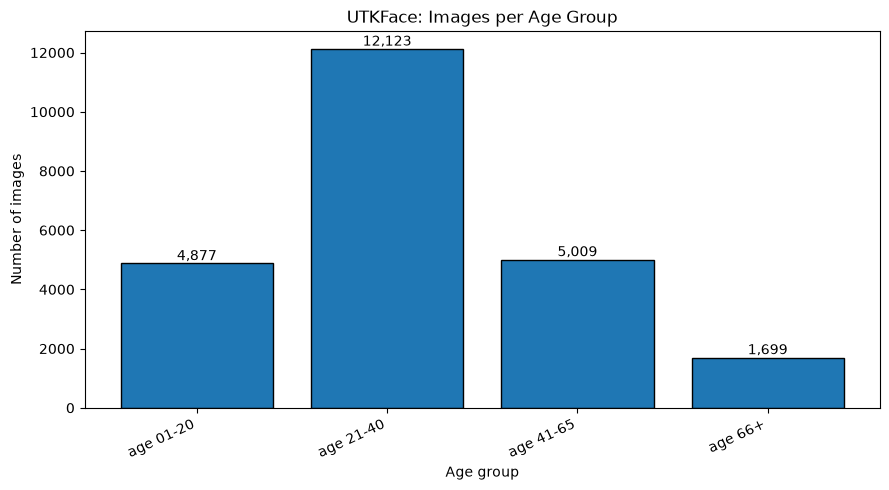

In [3]:

plt.figure(figsize=(9, 5))
plt.bar(class_counts.index, class_counts.values, edgecolor="black")
plt.title("UTKFace: Images per Age Group")
plt.xlabel("Age group")
plt.ylabel("Number of images")
plt.xticks(rotation=25, ha="right")

for i, count in enumerate(class_counts.values):
    plt.text(i, count, f"{count:,}", ha="center", va="bottom")

plt.tight_layout()
plt.show()


In [4]:

# Step 1: Reuse the eight-group train/validation/test split

from sklearn.model_selection import train_test_split

# Load the exact split used in the eight-group experiment.
SPLIT_FILE = PROJECT_FOLDER / "data/splits/UTKFace_8Groups_split_indices.csv"

if not SPLIT_FILE.exists():
    raise FileNotFoundError(
        f"Cannot find split file: {SPLIT_FILE}"
    )

split_table = pd.read_csv(SPLIT_FILE)

print("Loaded split records:", len(split_table))

# Convert the original age labels into four groups.
def age_to_four_groups(age):
    if 1 <= age <= 20:
        return "age 01-20"
    elif 21 <= age <= 40:
        return "age 21-40"
    elif 41 <= age <= 65:
        return "age 41-65"
    elif age >= 66:
        return "age 66+"
    else:
        return None

split_table["age_group_4"] = (
    split_table["age"].apply(age_to_four_groups)
)

# Define the order of the four classes.
four_group_order = [
    "age 01-20",
    "age 21-40",
    "age 41-65",
    "age 66+"
]

# Check that all records have valid labels.
assert split_table["age_group_4"].notna().all()

# Create separate data tables.
train_table = split_table[
    split_table["split"] == "train"
].copy()

validation_table = split_table[
    split_table["split"] == "validation"
].copy()

test_table = split_table[
    split_table["split"] == "test"
].copy()

# Display partition sizes.
print("\nPartition sizes:")
print("Training:", len(train_table))
print("Validation:", len(validation_table))
print("Test:", len(test_table))

# Display four-class distribution in each partition.
split_counts = pd.crosstab(
    split_table["age_group_4"],
    split_table["split"]
).reindex(four_group_order)

print("\nFour-group distribution:")
display(split_counts)

# Verify that the partitions do not overlap.
train_files = set(train_table["file_name"])
validation_files = set(validation_table["file_name"])
test_files = set(test_table["file_name"])

assert train_files.isdisjoint(validation_files)
assert train_files.isdisjoint(test_files)
assert validation_files.isdisjoint(test_files)

assert len(train_files | validation_files | test_files) == len(split_table)

print("\nSplit verification passed!")
print("No image appears in multiple partitions.")

# Save the four-group split.
split_table.to_csv(
    PROJECT_FOLDER / "data/splits/UTKFace_4Groups_split_indices.csv",
    index=False
)

print("\nSaved: data/splits/UTKFace_4Groups_split_indices.csv")


Loaded split records: 23708

Partition sizes:
Training: 16594
Validation: 3557
Test: 3557

Four-group distribution:


split,test,train,validation
age_group_4,,,
age 01-20,732,3413,732
age 21-40,1819,8485,1819
age 41-65,751,3507,751
age 66+,255,1189,255



Split verification passed!
No image appears in multiple partitions.

Saved: data/splits/UTKFace_4Groups_split_indices.csv


In [5]:

import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

# Four age groups
LABEL_NAMES = [
    "age 01-20",
    "age 21-40",
    "age 41-65",
    "age 66+"
]

label_to_id = {
    label: index
    for index, label in enumerate(LABEL_NAMES)
}

# Image preprocessing
# Keep the same settings as the eight-group experiment.
image_transform = transforms.Compose([
    transforms.Resize((200, 200)),
    transforms.ToTensor()
])

class UTKFaceDataset(Dataset):
    def __init__(self, table, transform):
        self.table = table.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.table)

    def __getitem__(self, index):
        row = self.table.iloc[index]

        # Load and preprocess image
        image_path = UTKFACE_FOLDER / row["file_name"]

        with Image.open(image_path) as image:
            image = image.convert("RGB")
            image_tensor = self.transform(image)

        # Convert four-group label into a numeric ID
        label_id = label_to_id[row["age_group_4"]]

        return image_tensor, torch.tensor(
            label_id,
            dtype=torch.long
        )


# Create datasets
train_dataset = UTKFaceDataset(
    train_table, image_transform
)

validation_dataset = UTKFaceDataset(
    validation_table, image_transform
)

test_dataset = UTKFaceDataset(
    test_table, image_transform
)

# Keep the same batch size as the eight-group experiment
BATCH_SIZE = 64

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

validation_loader = DataLoader(
    validation_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

# Check one batch
images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print(
    "Pixel value range:",
    images.min().item(),
    "to",
    images.max().item()
)
print("First 10 numeric labels:", labels[:10].tolist())


Image batch shape: torch.Size([64, 3, 200, 200])
Label batch shape: torch.Size([64])
Pixel value range: 0.0 to 1.0
First 10 numeric labels: [1, 1, 1, 1, 1, 1, 1, 2, 1, 0]


In [6]:

from torch import nn

class SmallAgeCNN(nn.Module):
    def __init__(self, number_of_classes):
        super().__init__()

        self.features = nn.Sequential(
            # First convolution block
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # Second convolution block
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # Third convolution block
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # Global average pooling
            nn.AdaptiveAvgPool2d((1, 1))
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(p=0.30),
            nn.Linear(128, number_of_classes)
        )

    def forward(self, images):
        features = self.features(images)
        return self.classifier(features)


# Select GPU if available
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# Initialize the four-class model
model = SmallAgeCNN(
    number_of_classes=len(LABEL_NAMES)
).to(device)

print("Device:", device)
print(model)

trainable_parameters = sum(
    parameter.numel()
    for parameter in model.parameters()
    if parameter.requires_grad
)

print("\nTrainable parameters:", trainable_parameters)


Device: cuda
SmallAgeCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (9): AdaptiveAvgPool2d(output_size=(1, 1))
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Dropout(p=0.3, inplace=False)
    (2): Linear(in_features=128, out_features=4, bias=True)
  )
)

Trainable parameters: 93764


## Train the Four-Group CNN

The CNN architecture follows the eight-group experiment. Only the output layer changes from eight classes to four classes.

Class weights are calculated from the training partition only. The best checkpoint is selected using validation macro-F1. The test set is kept separate until final evaluation.

In [7]:

from sklearn.metrics import accuracy_score, f1_score

# Reproducibility
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Calculate class weights using training data only.
train_label_ids = train_table["age_group_4"].map(label_to_id).to_numpy()
train_counts = np.bincount(train_label_ids, minlength=len(LABEL_NAMES))

if np.any(train_counts == 0):
    raise ValueError("At least one age group has no training samples.")

class_weights = len(train_label_ids) / (len(LABEL_NAMES) * train_counts)
class_weights_tensor = torch.tensor(
    class_weights, dtype=torch.float32, device=device
)

display(pd.DataFrame({
    "age_group": LABEL_NAMES,
    "training_images": train_counts,
    "loss_weight": class_weights.round(4)
}))

loss_function = nn.CrossEntropyLoss(weight=class_weights_tensor)

LEARNING_RATE = 1e-3
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)

@torch.no_grad()
def evaluate_model(model, data_loader):
    model.eval()
    true_labels, predicted_labels = [], []
    total_loss, total_images = 0.0, 0

    for batch_images, batch_labels in data_loader:
        batch_images = batch_images.to(device)
        batch_labels = batch_labels.to(device)

        logits = model(batch_images)
        batch_loss = loss_function(logits, batch_labels)

        total_loss += batch_loss.item() * batch_labels.size(0)
        total_images += batch_labels.size(0)

        predictions = logits.argmax(dim=1)
        true_labels.extend(batch_labels.cpu().numpy())
        predicted_labels.extend(predictions.cpu().numpy())

    return {
        "loss": total_loss / total_images,
        "accuracy": accuracy_score(true_labels, predicted_labels),
        "macro_f1": f1_score(
            true_labels, predicted_labels,
            average="macro", zero_division=0
        ),
        "true_labels": np.asarray(true_labels),
        "predicted_labels": np.asarray(predicted_labels)
    }

print("Class weights:", class_weights.round(4))
print("Learning rate:", LEARNING_RATE)


,age_group,training_images,loss_weight
0,age 01-20,3413,1.2155
1,age 21-40,8485,0.4889
2,age 41-65,3507,1.1829
3,age 66+,1189,3.4891


Class weights: [1.2155 0.4889 1.1829 3.4891]
Learning rate: 0.001


In [8]:

# Reset model and optimizer with the fixed seed before training.
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

model = SmallAgeCNN(number_of_classes=len(LABEL_NAMES)).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)

EPOCHS = 10
best_validation_macro_f1 = -1.0
best_model_path = PROJECT_FOLDER / "models/utkface_4groups_cnn_best.pt"
training_history = []

for epoch in range(1, EPOCHS + 1):
    model.train()
    running_loss, images_seen = 0.0, 0

    for batch_images, batch_labels in train_loader:
        batch_images = batch_images.to(device)
        batch_labels = batch_labels.to(device)

        optimizer.zero_grad()
        logits = model(batch_images)
        loss = loss_function(logits, batch_labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * batch_labels.size(0)
        images_seen += batch_labels.size(0)

    train_loss = running_loss / images_seen
    validation_results = evaluate_model(model, validation_loader)

    training_history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "validation_loss": validation_results["loss"],
        "validation_accuracy": validation_results["accuracy"],
        "validation_macro_f1": validation_results["macro_f1"]
    })

    if validation_results["macro_f1"] > best_validation_macro_f1:
        best_validation_macro_f1 = validation_results["macro_f1"]
        torch.save({
            "model_state_dict": model.state_dict(),
            "label_names": LABEL_NAMES,
            "seed": SEED,
            "validation_macro_f1": best_validation_macro_f1,
            "image_size": [200, 200],
            "architecture": "SmallAgeCNN"
        }, best_model_path)

    print(
        f"Epoch {epoch:02d}/{EPOCHS} | "
        f"train loss: {train_loss:.4f} | "
        f"val loss: {validation_results['loss']:.4f} | "
        f"val accuracy: {validation_results['accuracy']:.4f} | "
        f"val macro-F1: {validation_results['macro_f1']:.4f}"
    )

history_table = pd.DataFrame(training_history)
history_csv = PROJECT_FOLDER / "results/tables/UTKFace_4Groups_training_history.csv"
history_table.to_csv(history_csv, index=False)

print("\nBest validation macro-F1:", round(best_validation_macro_f1, 4))
print("Best checkpoint:", best_model_path)
print("Training history:", history_csv)


Epoch 01/10 | train loss: 1.3591 | val loss: 1.3268 | val accuracy: 0.3958 | val macro-F1: 0.3068
Epoch 02/10 | train loss: 1.3362 | val loss: 1.3349 | val accuracy: 0.4650 | val macro-F1: 0.2838
Epoch 03/10 | train loss: 1.3219 | val loss: 1.2937 | val accuracy: 0.4585 | val macro-F1: 0.3844
Epoch 04/10 | train loss: 1.2942 | val loss: 1.2795 | val accuracy: 0.4920 | val macro-F1: 0.3848
Epoch 05/10 | train loss: 1.2791 | val loss: 1.2661 | val accuracy: 0.4906 | val macro-F1: 0.3918
Epoch 06/10 | train loss: 1.2669 | val loss: 1.2392 | val accuracy: 0.4529 | val macro-F1: 0.3943
Epoch 07/10 | train loss: 1.2484 | val loss: 1.2648 | val accuracy: 0.3885 | val macro-F1: 0.3484
Epoch 08/10 | train loss: 1.2390 | val loss: 1.3129 | val accuracy: 0.2615 | val macro-F1: 0.2594
Epoch 09/10 | train loss: 1.2301 | val loss: 1.2054 | val accuracy: 0.3857 | val macro-F1: 0.3813
Epoch 10/10 | train loss: 1.1969 | val loss: 1.1744 | val accuracy: 0.5552 | val macro-F1: 0.4653

Best validation mac

## Review Training Performance

The learning curves help identify whether the model is learning and whether the training and validation results begin to diverge.

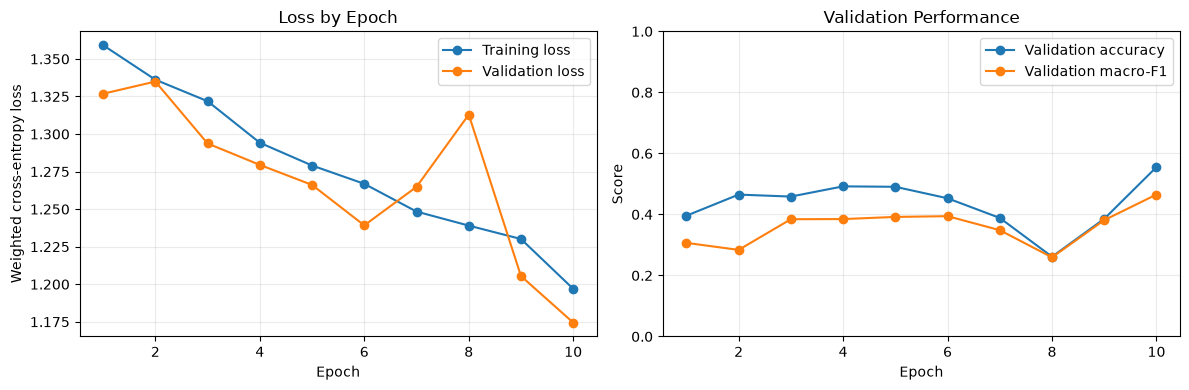

In [9]:

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history_table["epoch"], history_table["train_loss"],
             marker="o", label="Training loss")
axes[0].plot(history_table["epoch"], history_table["validation_loss"],
             marker="o", label="Validation loss")
axes[0].set_title("Loss by Epoch")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Weighted cross-entropy loss")
axes[0].legend()
axes[0].grid(alpha=0.25)

axes[1].plot(history_table["epoch"], history_table["validation_accuracy"],
             marker="o", label="Validation accuracy")
axes[1].plot(history_table["epoch"], history_table["validation_macro_f1"],
             marker="o", label="Validation macro-F1")
axes[1].set_title("Validation Performance")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Score")
axes[1].set_ylim(0, 1)
axes[1].legend()
axes[1].grid(alpha=0.25)

plt.tight_layout()
plt.show()


## Final Test Evaluation

Load the checkpoint with the best validation macro-F1 and evaluate it on the test partition. The test partition is not used for training or checkpoint selection.

In [10]:

from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import json

checkpoint = torch.load(
    best_model_path,
    map_location=device,
    weights_only=False
)
model.load_state_dict(checkpoint["model_state_dict"])

test_results = evaluate_model(model, test_loader)

print("Test accuracy:", round(test_results["accuracy"], 4))
print("Test macro-F1:", round(test_results["macro_f1"], 4))
print("\nPer-class classification report:")

report_text = classification_report(
    test_results["true_labels"],
    test_results["predicted_labels"],
    labels=list(range(len(LABEL_NAMES))),
    target_names=LABEL_NAMES,
    zero_division=0,
    digits=4
)
print(report_text)

report_dict = classification_report(
    test_results["true_labels"],
    test_results["predicted_labels"],
    labels=list(range(len(LABEL_NAMES))),
    target_names=LABEL_NAMES,
    output_dict=True,
    zero_division=0
)

report_path = PROJECT_FOLDER / "results/tables/UTKFace_4Groups_test_report.csv"
pd.DataFrame(report_dict).transpose().to_csv(report_path)


Test accuracy: 0.5718
Test macro-F1: 0.4956

Per-class classification report:
              precision    recall  f1-score   support

   age 01-20     0.5181    0.6052    0.5583       732
   age 21-40     0.6856    0.6905    0.6880      1819
   age 41-65     0.3770    0.3182    0.3451       751
     age 66+     0.4068    0.3765    0.3910       255

    accuracy                         0.5718      3557
   macro avg     0.4969    0.4976    0.4956      3557
weighted avg     0.5660    0.5718    0.5676      3557



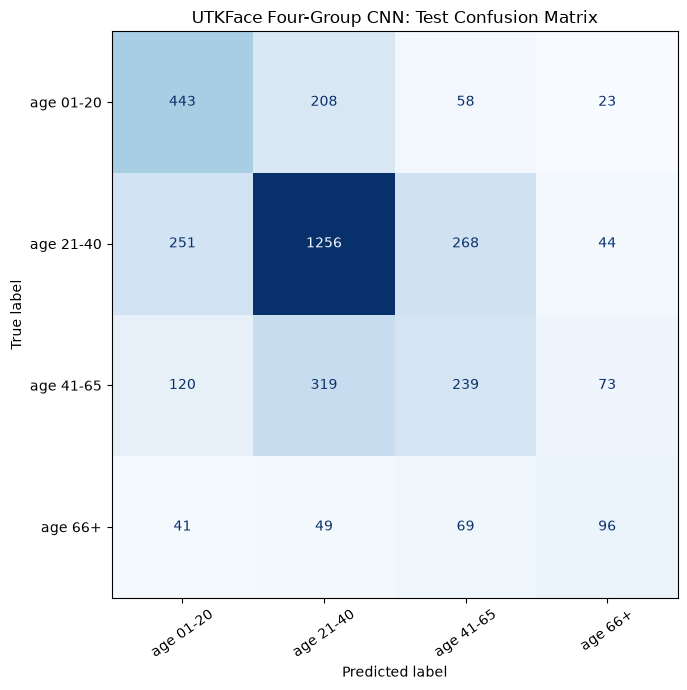

Saved test report: C:\Users\ASUS\Downloads\ENGR418_Facial_Age_Group_Estimation\results/tables/UTKFace_4Groups_test_report.csv
Saved confusion matrix: C:\Users\ASUS\Downloads\ENGR418_Facial_Age_Group_Estimation\results/tables/UTKFace_4Groups_confusion_matrix.csv
Saved test summary: C:\Users\ASUS\Downloads\ENGR418_Facial_Age_Group_Estimation\results/tables/UTKFace_4Groups_test_results.json


In [11]:

# Confusion matrix
cm = confusion_matrix(
    test_results["true_labels"],
    test_results["predicted_labels"],
    labels=list(range(len(LABEL_NAMES)))
)

plt.figure(figsize=(8, 7))
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=LABEL_NAMES
).plot(
    cmap="Blues",
    values_format="d",
    xticks_rotation=35,
    ax=plt.gca(),
    colorbar=False
)
plt.title("UTKFace Four-Group CNN: Test Confusion Matrix")
plt.tight_layout()
plt.show()

confusion_matrix_table = pd.DataFrame(
    cm, index=LABEL_NAMES, columns=LABEL_NAMES
)
confusion_matrix_path = PROJECT_FOLDER / "results/tables/UTKFace_4Groups_confusion_matrix.csv"
confusion_matrix_table.to_csv(confusion_matrix_path)

# Save a compact machine-readable summary of the final test metrics.
summary = {
    "dataset": "UTKFace",
    "number_of_images": int(len(split_table)),
    "number_of_classes": len(LABEL_NAMES),
    "label_names": LABEL_NAMES,
    "test_accuracy": float(test_results["accuracy"]),
    "test_macro_f1": float(test_results["macro_f1"]),
    "best_validation_macro_f1": float(checkpoint["validation_macro_f1"]),
    "seed": SEED,
    "epochs": EPOCHS,
    "batch_size": BATCH_SIZE,
    "learning_rate": LEARNING_RATE
}

summary_path = PROJECT_FOLDER / "results/tables/UTKFace_4Groups_test_results.json"
with open(summary_path, "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=2)

print("Saved test report:", report_path)
print("Saved confusion matrix:", confusion_matrix_path)
print("Saved test summary:", summary_path)


## Interpretation and Limitations

- This experiment predicts one of four age groups from a face image; it does not predict an exact age.
- The four labels are 01–20, 21–40, 41–65, and 66+.
- The same CNN architecture and the same train/validation/test partition are retained from the eight-group experiment to support a controlled comparison.
- Accuracy gives the overall proportion of correct predictions. Macro-F1 gives equal importance to each class, which is useful when class sizes differ.
- The confusion matrix shows which age groups are most frequently confused.
- Results should be interpreted as age-group estimates on this dataset, not as a reliable determination of a person's actual age.
- The notebook has not been trained as part of this file-completion step. Run all cells from top to bottom to generate the actual performance metrics and saved model checkpoint.